# Forecasting PM2.5 and PM10 and risk classes for four industrial cities of Kazakhstan (pilot)

Simplified version of the notebook: same steps and settings as the main version, so the results are identical.
The code runs top to bottom and every step is explained.

**Plan:**
1. Download air-quality data (AirData.kz) and weather data (Open-Meteo)
2. Clean the data
3. Build features and split into train / validation / test
4. Train 4 models + a baseline
5. Compute metrics, confidence intervals and the Diebold–Mariano test
6. Convert forecasts into risk classes (safe / moderate / dangerous)
7. Additional analyses: by city, by season, SHAP
8. Error analysis

**How to run:** Runtime → Change runtime type → T4 GPU, then Runtime → Run all (~20–30 minutes).

## 0. Settings
Everything that can be changed is collected here.

In [2]:

DATA_URL = "https://raw.githubusercontent.com/qazybekb/AirDatakz-OpenData/main"


CITIES = {
    "Temirtau":  {"station": 200, "start": "2022-01-01", "end": "2025-12-31", "lat": 50.057988, "lon": 72.956546},
    "Pavlodar":  {"station": 48,  "start": "2022-01-01", "end": "2025-12-31", "lat": 52.29491,  "lon": 76.94278},
    "Oskemen":   {"station": 240, "start": "2022-01-01", "end": "2025-12-31", "lat": 49.978389, "lon": 82.635583},

    "Karaganda": {"station": None, "start": "2018-01-01", "end": "2021-12-31", "lat": 49.8047, "lon": 73.1094},
}
CITY_NAMES = list(CITIES)

POLLUTANTS = ["pm25", "pm10"]
HORIZONS = [1, 24]
SEEDS = [0, 1, 2, 3, 4]
RF_TREES = 100
SVR_MAX_TRAIN = 8000
N_BOOT = 1000
RUN_LSTM = True
RUN_SHAP = True


WHO = {"pm25": (15.0, 37.5), "pm10": (45.0, 75.0)}
CLASS_NAMES = ["safe", "moderate", "dangerous"]

OUT = "/content/results"

In [3]:
import os, time, json, zipfile, warnings
warnings.filterwarnings("ignore")
os.system("pip install -q shap")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from scipy import stats
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             precision_recall_fscore_support, confusion_matrix)
import xgboost as xgb

os.makedirs(OUT + "/figures", exist_ok=True)
os.makedirs(OUT + "/tables", exist_ok=True)
start_time = time.time()

## 1. Air-quality data
In the AirData files one row = one station for one hour. Time is stored in UTC and converted to local time (UTC+5).
Temirtau, Pavlodar and Oskemen (Ust-Kamenogorsk) are in the shared `rest_of_kz` file; Karaganda has its own folder.

In [4]:
cols = ["datetime_utc", "station_id", "city", "value_ugm3"]
rest = {
    "pm25": pd.read_csv(DATA_URL + "/rest_of_kz/pm2_5.csv.gz", usecols=cols),
    "pm10": pd.read_csv(DATA_URL + "/rest_of_kz/pm10.csv.gz", usecols=cols),
}
kar = {
    "pm25": pd.read_csv(DATA_URL + "/karaganda/pm25.csv.gz"),
    "pm10": pd.read_csv(DATA_URL + "/karaganda/pm10.csv.gz"),
}

def hourly_series(raw, start, end):
    """Converts time to local time and builds one series: the mean value for every hour."""
    t = pd.to_datetime(raw["datetime_utc"], utc=True).dt.tz_localize(None) + pd.Timedelta(hours=5)
    raw = raw.assign(t=t.dt.floor("h"))
    raw = raw[(raw.t >= start) & (raw.t < pd.Timestamp(end) + pd.Timedelta(days=1))]
    return raw.groupby("t")["value_ugm3"].mean()

pm = {}
for city, c in CITIES.items():
    pm[city] = {}
    for p in POLLUTANTS:
        if city == "Karaganda":
            raw = kar[p][kar[p]["source"].isin(["kgmt", "kgmt_auto"])]
        else:
            raw = rest[p][(rest[p]["city"] == city) & (rest[p]["station_id"] == c["station"])]
        pm[city][p] = hourly_series(raw, c["start"], c["end"])
    print(city, "PM2.5 hours:", len(pm[city]["pm25"]), " PM10 hours:", len(pm[city]["pm10"]))

Temirtau PM2.5 hours: 21262  PM10 hours: 21949
Pavlodar PM2.5 hours: 20621  PM10 hours: 21458
Oskemen PM2.5 hours: 25789  PM10 hours: 29320
Karaganda PM2.5 hours: 14852  PM10 hours: 9943


## 2. Weather (Open-Meteo, ERA5)
Download temperature, relative humidity and wind speed at the station coordinates, one year per request.

In [5]:
def get_weather(lat, lon, start, end):
    parts = []
    for year in range(int(start[:4]), int(end[:4]) + 1):
        params = {"latitude": lat, "longitude": lon, "timezone": "GMT",
                  "start_date": max(start, f"{year}-01-01"), "end_date": min(end, f"{year}-12-31"),
                  "hourly": "temperature_2m,relative_humidity_2m,wind_speed_10m"}
        r = requests.get("https://archive-api.open-meteo.com/v1/archive", params=params, timeout=120)
        r.raise_for_status()
        parts.append(pd.DataFrame(r.json()["hourly"]))
    w = pd.concat(parts, ignore_index=True)
    w["time"] = pd.to_datetime(w["time"]) + pd.Timedelta(hours=5)
    w = w.set_index("time")
    return w.rename(columns={"temperature_2m": "temp", "relative_humidity_2m": "rh", "wind_speed_10m": "wind"})


data = {}
for city, c in CITIES.items():
    w = get_weather(c["lat"], c["lon"], c["start"], c["end"])
    hours = pd.date_range(c["start"], pd.Timestamp(c["end"]) + pd.Timedelta(hours=23), freq="h")
    df = pd.DataFrame({"pm25": pm[city]["pm25"], "pm10": pm[city]["pm10"]}).reindex(hours)
    data[city] = df.join(w.reindex(hours))
data["Temirtau"].head()

,pm25,pm10,temp,rh,wind
2022-01-01 00:00:00,NaN,579.700,NaN,NaN,NaN
2022-01-01 01:00:00,NaN,569.175,NaN,NaN,NaN
2022-01-01 02:00:00,NaN,284.175,NaN,NaN,NaN
2022-01-01 03:00:00,NaN,179.700,NaN,NaN,NaN
2022-01-01 04:00:00,NaN,123.075,NaN,NaN,NaN


## 3. Data cleaning
1. Remove impossible values: negative, above the sensor range, a stuck sensor
   (the same value for 12 hours in a row), and hours where PM2.5 > PM10 (PM2.5 is part of PM10).
2. Short gaps (up to 3 hours) are filled by interpolation; longer gaps stay empty and those hours are not used.

High values are deliberately **not** removed: pollution peaks are exactly what the warning system has to detect.

In [6]:
def stuck_sensor(s, n_hours=12):
    """True where the same value repeats for n_hours or more in a row."""
    group = (s != s.shift()).cumsum()
    run_length = s.groupby(group).transform("size")
    return s.notna() & (run_length >= n_hours)

def fill_short_gaps(s, max_gap=3):
    """Interpolates only gaps of length <= max_gap hours."""
    missing = s.isna()
    group = (missing != missing.shift()).cumsum()
    gap_length = missing.groupby(group).transform("sum")
    filled = s.interpolate(method="time", limit_area="inside")
    to_fill = missing & (gap_length <= max_gap)
    s = s.copy()
    s[to_fill] = filled[to_fill]
    return s, int(to_fill.sum())

clean_report = []
for city, df in data.items():
    row = {"city": city, "hours with PM2.5 and PM10": int(df[POLLUTANTS].notna().all(axis=1).sum())}
    for p, max_value in [("pm25", 1000), ("pm10", 2000)]:
        bad = (df[p] < 0) | (df[p] > max_value) | stuck_sensor(df[p])
        row[f"{p} impossible removed"] = int(bad.sum())
        df.loc[bad, p] = np.nan
    bad = df["pm25"] > df["pm10"]
    row["PM2.5 > PM10 removed"] = int(bad.sum())
    df.loc[bad, POLLUTANTS] = np.nan
    df.loc[(df.rh < 0) | (df.rh > 100), "rh"] = np.nan
    for col in ["pm25", "pm10", "temp", "rh", "wind"]:
        df[col], n_filled = fill_short_gaps(df[col])
        if col in POLLUTANTS: row[f"{col} interpolated"] = n_filled
    row["hours still missing (not used)"] = int(df[["pm25", "pm10", "temp", "rh", "wind"]].isna().any(axis=1).sum())
    clean_report.append(row)
clean_report = pd.DataFrame(clean_report)
clean_report.to_csv(OUT + "/tables/cleaning_report.csv", index=False)
clean_report

,city,hours with PM2.5 and PM10,pm25 impossible removed,pm10 impossible removed,PM2.5 > PM10 removed,pm25 interpolated,pm10 interpolated,hours still missing (not used)
0,Temirtau,21000,0,13,2,437,455,13642
1,Pavlodar,20618,0,0,0,145,153,14298
2,Oskemen,25779,0,0,20,94,113,9205
3,Karaganda,7686,0,0,501,315,196,27691


## 4. Features, targets and split
**Features at time t:** PM2.5 and PM10 now, one hour ago and one day ago; temperature, humidity, wind;
hour of day (as sin/cos, so that 23:00 and 00:00 are close); season; city (one-hot).

**Target:** the value 1 hour later (t+1) and 24 hours later (t+24).

**Risk class:** take the mean of the last 24 hours and compare it with the WHO thresholds;
the final class is the worse of the two pollutants.

**Split:** inside each city, in time order: 70% train, 15% validation, 15% test,
so the model never sees the future.

In [7]:
def risk_class(pm25_24h, pm10_24h):
    """0 = safe, 1 = moderate, 2 = dangerous; the worse class of PM2.5 and PM10 is used."""
    classes = []
    for x, p in [(pm25_24h, "pm25"), (pm10_24h, "pm10")]:
        x = np.asarray(x, float)
        c = np.where(x <= WHO[p][0], 0, np.where(x <= WHO[p][1], 1, 2)).astype(float)
        c[np.isnan(x)] = np.nan
        classes.append(c)
    worst = np.fmax(classes[0], classes[1])
    worst[np.isnan(classes[0]) | np.isnan(classes[1])] = np.nan
    return worst

season_of_month = {12: "winter", 1: "winter", 2: "winter", 3: "spring", 4: "spring", 5: "spring",
                   6: "summer", 7: "summer", 8: "summer", 9: "autumn", 10: "autumn", 11: "autumn"}

all_cities = []
for city, df in data.items():
    df = df.copy()
    df["city"] = city
    df["time"] = df.index
    df["season"] = df.index.month.map(season_of_month)
    df["hour_sin"] = np.sin(2 * np.pi * df.index.hour / 24)
    df["hour_cos"] = np.cos(2 * np.pi * df.index.hour / 24)
    for s in ["winter", "spring", "summer", "autumn"]:
        df["season_" + s] = (df["season"] == s).astype(float)
    for name in CITY_NAMES:
        df["city_" + name] = float(name == city)
    for p in POLLUTANTS:
        df[p + "_lag1"] = df[p].shift(1)
        df[p + "_lag24"] = df[p].shift(24)
        for h in HORIZONS:
            df[f"y_{p}_h{h}"] = df[p].shift(-h)
    mean24 = df[POLLUTANTS].rolling(24, min_periods=24).mean()
    df["obs_class"] = risk_class(mean24["pm25"], mean24["pm10"])

    complete = df[["pm25", "pm10", "temp", "rh", "wind"]].notna().all(axis=1)
    last_25_ok = complete.rolling(25, min_periods=25).sum() == 25
    targets_ok = df[[f"y_{p}_h{h}" for p in POLLUTANTS for h in HORIZONS]].notna().all(axis=1)
    df["valid"] = last_25_ok & targets_ok


    rows = np.where(df["valid"])[0]
    n = len(rows)
    df["split"] = ""
    df.iloc[rows[:int(0.70 * n)], df.columns.get_loc("split")] = "train"
    df.iloc[rows[int(0.70 * n):int(0.85 * n)], df.columns.get_loc("split")] = "val"
    df.iloc[rows[int(0.85 * n):], df.columns.get_loc("split")] = "test"
    all_cities.append(df.reset_index(drop=True))

D = pd.concat(all_cities, ignore_index=True)

FEATURES = (["pm25", "pm10", "temp", "rh", "wind",
             "pm25_lag1", "pm25_lag24", "pm10_lag1", "pm10_lag24",
             "hour_sin", "hour_cos", "season_winter", "season_spring", "season_summer", "season_autumn"]
            + ["city_" + c for c in CITY_NAMES])

train_rows = np.where(D["split"] == "train")[0]
val_rows = np.where(D["split"] == "val")[0]
test_rows = np.where(D["split"] == "test")[0]
X_train, X_val, X_test = D.loc[train_rows, FEATURES].values, D.loc[val_rows, FEATURES].values, D.loc[test_rows, FEATURES].values
print("train:", len(train_rows), " val:", len(val_rows), " test:", len(test_rows))

train: 45474  val: 9744  test: 9746


In [8]:

summary = []
for city in CITY_NAMES:
    g = D[(D.city == city) & D.valid]
    row = {"city": city}
    for part in ["train", "val", "test"]:
        gp = g[g.split == part]
        row[part] = f"{len(gp)} ({gp.time.min():%m.%Y}-{gp.time.max():%m.%Y})"
    row["PM2.5 mean±sd"] = f"{g.pm25.mean():.1f} ± {g.pm25.std():.1f}"
    row["PM10 mean±sd"] = f"{g.pm10.mean():.1f} ± {g.pm10.std():.1f}"
    cls = g["obs_class"].dropna()
    row["safe/moderate/dangerous %"] = " / ".join(f"{100 * (cls == i).mean():.0f}" for i in range(3))
    summary.append(row)
summary = pd.DataFrame(summary)
summary.to_csv(OUT + "/tables/table1_dataset.csv", index=False)
summary

,city,train,val,test,PM2.5 mean±sd,PM10 mean±sd,safe/moderate/dangerous %
0,Temirtau,11827 (02.2022-01.2025),2534 (01.2025-05.2025),2535 (05.2025-12.2025),19.6 ± 29.4,27.2 ± 39.5,60 / 31 / 8
1,Pavlodar,13895 (02.2022-04.2025),2977 (04.2025-08.2025),2978 (08.2025-12.2025),13.2 ± 14.2,26.5 ± 27.7,73 / 23 / 4
2,Oskemen,15492 (02.2022-11.2024),3320 (11.2024-04.2025),3320 (04.2025-12.2025),30.1 ± 46.6,37.8 ± 51.4,50 / 24 / 26
3,Karaganda,4260 (01.2018-10.2018),913 (10.2018-11.2020),913 (11.2020-02.2021),23.0 ± 28.2,57.6 ± 74.0,30 / 45 / 25


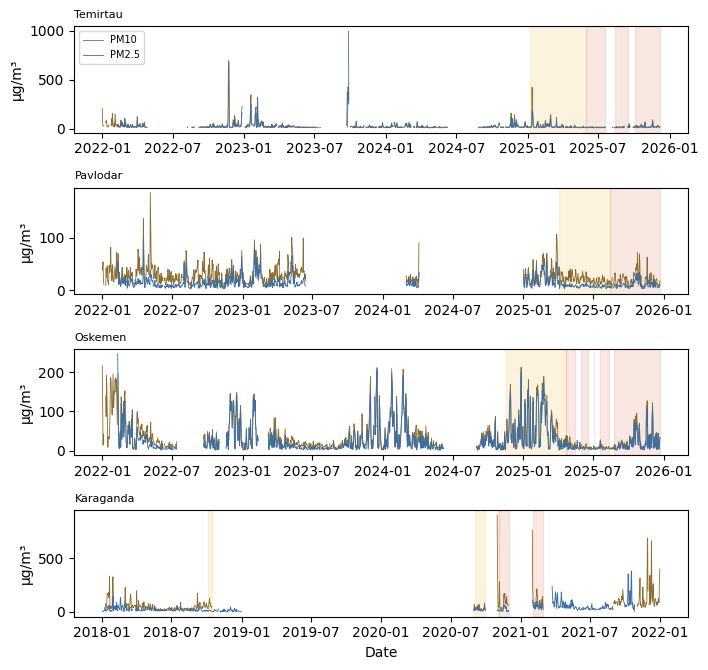

In [9]:

fig, axes = plt.subplots(4, 1, figsize=(7.2, 6.8))
for ax, city in zip(axes, CITY_NAMES):
    g = D[D.city == city].set_index("time")
    daily = g[POLLUTANTS].resample("D").mean()
    ax.plot(daily.index, daily["pm10"], lw=0.6, color="#8c6d31", label="PM10")
    ax.plot(daily.index, daily["pm25"], lw=0.6, color="#3b6ea5", label="PM2.5")
    for part, color in [("val", "#f2c14e"), ("test", "#e07a5f")]:
        t = g.index[g.split == part]
        breaks = np.where(np.diff(t.values) > np.timedelta64(240, "h"))[0]
        for a, b in zip(np.r_[0, breaks + 1], np.r_[breaks, len(t) - 1]):
            ax.axvspan(t[a], t[b], color=color, alpha=0.18)
    ax.set_title(city, fontsize=8, loc="left")
    ax.set_ylabel("µg/m³")
axes[0].legend(fontsize=7)
axes[-1].set_xlabel("Date")
plt.tight_layout(); plt.savefig(OUT + "/figures/fig1_timeseries_split.pdf"); plt.show()

## 5. Models
- **Baseline (persistence):** "the value at this hour tomorrow will be the same as now". A model is useful only if it beats this.
- **XGBoost** and **Random Forest:** tree ensembles.
- **SVR:** a classical model; the data are standardised before it.
- **LSTM:** a neural network that reads the last 12 or 24 hours as a sequence.

For each model several settings are tried on **validation** (seed 0) and the one with the lowest RMSE is kept;
then it is trained with 5 different seeds and evaluated on **test**. The final forecast is the mean over seeds.

In [10]:
def metrics(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
            "R2": r2_score(y_true, y_pred)}

def target(rows, p, h):
    return D.loc[rows, f"y_{p}_h{h}"].values


svr_rows = np.sort(np.random.default_rng(0).choice(len(train_rows), min(SVR_MAX_TRAIN, len(train_rows)), replace=False))

def make_model(name, setting, seed):
    if name == "XGBoost":
        return xgb.XGBRegressor(n_estimators=setting["n_estimators"], max_depth=setting["max_depth"], learning_rate=0.05,
                                subsample=0.8, colsample_bytree=0.8, tree_method="hist", random_state=seed, n_jobs=-1)
    if name == "Random Forest":
        return RandomForestRegressor(n_estimators=RF_TREES, max_depth=setting["max_depth"], min_samples_leaf=5,
                                     max_features=0.5, random_state=seed, n_jobs=-1)
    if name == "SVR":
        svr = make_pipeline(StandardScaler(), SVR(kernel=setting["kernel"], C=10, epsilon=0.1, max_iter=200000))
        return TransformedTargetRegressor(svr, transformer=StandardScaler())

SETTINGS = {
    "XGBoost": [{"n_estimators": 300, "max_depth": 4}, {"n_estimators": 300, "max_depth": 6},
                {"n_estimators": 600, "max_depth": 4}, {"n_estimators": 600, "max_depth": 6}],
    "Random Forest": [{"max_depth": 15}, {"max_depth": None}],
    "SVR": [{"kernel": "rbf"}, {"kernel": "linear"}],
}

def fit_predict(name, setting, seed, p, h):
    """Trains one tabular model and returns forecasts for validation and test."""
    y_train = target(train_rows, p, h)
    if name == "SVR":
        model = make_model(name, setting, seed).fit(X_train[svr_rows], y_train[svr_rows])
    else:
        model = make_model(name, setting, seed).fit(X_train, y_train)
    return model.predict(X_val), model.predict(X_test), model

### LSTM
LSTM input: the last W hours (W = 12 or 24) of all features without lags, standardised with the training data.
The window never crosses into another city: every sample has 24 complete hours of its own city.

In [11]:
SEQ_COLS = (["pm25", "pm10", "temp", "rh", "wind", "hour_sin", "hour_cos",
             "season_winter", "season_spring", "season_summer", "season_autumn"]
            + ["city_" + c for c in CITY_NAMES])

if RUN_LSTM:
    import tensorflow as tf
    train_part = D[D.split == "train"]
    mean, std = train_part[SEQ_COLS].mean(), train_part[SEQ_COLS].std().replace(0, 1)
    seq_data = ((D[SEQ_COLS] - mean) / std).fillna(0).values.astype("float32")

    def windows(rows, W):

        return np.stack([seq_data[rows - W + 1 + j] for j in range(W)], axis=1)

    def fit_predict_lstm(W, seed, p, h):
        tf.keras.utils.set_random_seed(seed)
        y_train, y_val = target(train_rows, p, h), target(val_rows, p, h)
        y_mean, y_std = y_train.mean(), y_train.std()
        model = tf.keras.Sequential([
            tf.keras.layers.Input((W, len(SEQ_COLS))),
            tf.keras.layers.LSTM(64),
            tf.keras.layers.Dropout(0.2),
            tf.keras.layers.Dense(32, activation="relu"),
            tf.keras.layers.Dense(1)])
        model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="mse")
        stop = tf.keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)
        model.fit(windows(train_rows, W), (y_train - y_mean) / y_std,
                  validation_data=(windows(val_rows, W), (y_val - y_mean) / y_std),
                  epochs=30, batch_size=512, callbacks=[stop], verbose=0)
        pred_val = model.predict(windows(val_rows, W), batch_size=4096, verbose=0).ravel() * y_std + y_mean
        pred_test = model.predict(windows(test_rows, W), batch_size=4096, verbose=0).ravel() * y_std + y_mean
        return pred_val, pred_test
    SETTINGS["LSTM"] = [{"window": 12}, {"window": 24}]

MODELS = ["Baseline", "XGBoost", "Random Forest", "SVR"] + (["LSTM"] if RUN_LSTM else [])

### Training (the longest cell)

In [12]:
pred = {}
seed_results = []
tuning_results = []
best_setting = {}
xgb_for_shap = {}

for p in POLLUTANTS:
    for h in HORIZONS:
        print(f"\n=== {p}, {h} h ahead ===")
        pred[(p, h)] = {}

        pred[(p, h)]["Baseline"] = {"val": D.loc[val_rows, p].values, "test": D.loc[test_rows, p].values}
        seed_results.append({"pollutant": p, "h": h, "model": "Baseline", "seed": "-",
                             **metrics(target(test_rows, p, h), pred[(p, h)]["Baseline"]["test"])})

        for name in MODELS[1:]:
            t0 = time.time()

            best, best_rmse = None, np.inf
            for setting in SETTINGS[name]:
                if name == "LSTM":
                    p_val = fit_predict_lstm(setting["window"], 0, p, h)[0]
                else:
                    p_val = fit_predict(name, setting, 0, p, h)[0]
                m = metrics(target(val_rows, p, h), p_val)
                tuning_results.append({"pollutant": p, "h": h, "model": name, "setting": json.dumps(setting), **m})
                if m["RMSE"] < best_rmse:
                    best, best_rmse = setting, m["RMSE"]
            best_setting[f"{p} h{h} {name}"] = best


            vals, tests = [], []
            for seed in ([0] if name == "SVR" else SEEDS):
                if name == "LSTM":
                    p_val, p_test = fit_predict_lstm(best["window"], seed, p, h)
                else:
                    p_val, p_test, model = fit_predict(name, best, seed, p, h)
                    if name == "XGBoost" and seed == 0:
                        xgb_for_shap[(p, h)] = model
                vals.append(p_val); tests.append(p_test)
                seed_results.append({"pollutant": p, "h": h, "model": name, "seed": seed,
                                     **metrics(target(test_rows, p, h), p_test)})
            pred[(p, h)][name] = {"val": np.mean(vals, axis=0), "test": np.mean(tests, axis=0)}
            print(f"  {name:13s} best={best}  val RMSE={best_rmse:.2f}  ({time.time() - t0:.0f} s)")

seed_results = pd.DataFrame(seed_results)
pd.DataFrame(tuning_results).to_csv(OUT + "/tables/tuning_validation.csv", index=False)
seed_results.to_csv(OUT + "/tables/test_metrics_per_seed.csv", index=False)


=== pm25, 1 h ahead ===
  XGBoost       best={'n_estimators': 300, 'max_depth': 4}  val RMSE=17.45  (29 s)
  Random Forest best={'max_depth': None}  val RMSE=17.18  (138 s)
  SVR           best={'kernel': 'linear'}  val RMSE=18.23  (63 s)


  LSTM          best={'window': 24}  val RMSE=16.67  (123 s)

=== pm25, 24 h ahead ===
  XGBoost       best={'n_estimators': 300, 'max_depth': 4}  val RMSE=32.02  (23 s)
  Random Forest best={'max_depth': 15}  val RMSE=32.14  (159 s)
  SVR           best={'kernel': 'rbf'}  val RMSE=34.39  (60 s)
  LSTM          best={'window': 12}  val RMSE=31.91  (51 s)

=== pm10, 1 h ahead ===
  XGBoost       best={'n_estimators': 300, 'max_depth': 4}  val RMSE=22.19  (12 s)
  Random Forest best={'max_depth': 15}  val RMSE=21.70  (119 s)
  SVR           best={'kernel': 'linear'}  val RMSE=23.01  (64 s)
  LSTM          best={'window': 24}  val RMSE=21.33  (126 s)

=== pm10, 24 h ahead ===
  XGBoost       best={'n_estimators': 300, 'max_depth': 4}  val RMSE=38.70  (12 s)
  Random Forest best={'max_depth': 15}  val RMSE=38.85  (115 s)
  SVR           best={'kernel': 'rbf'}  val RMSE=41.13  (54 s)
  LSTM          best={'window': 24}  val RMSE=39.33  (51 s)


## 6. RQ1 / RQ2: main table
For each model: mean ± standard deviation over 5 seeds and a 95% confidence interval.

**Block bootstrap:** many times (1000) a new test sample is built from random blocks of 24 consecutive hours
and the metric is recomputed. The 2.5% and 97.5% percentiles give the 95% interval. Blocks are used instead of
single hours because neighbouring hours are similar, and an ordinary bootstrap would give a too narrow interval.

In [13]:
def bootstrap_ci(y_true, y_pred, n_boot=N_BOOT, block=24, seed=42):
    rng = np.random.default_rng(seed)
    n = len(y_true)
    n_blocks = int(np.ceil(n / block))
    results = {"MAE": [], "RMSE": [], "R2": []}
    for _ in range(n_boot):
        starts = rng.integers(0, n - block + 1, n_blocks)
        idx = (starts[:, None] + np.arange(block)).ravel()[:n]
        m = metrics(y_true[idx], y_pred[idx])
        for k in results:
            results[k].append(m[k])
    return {k: (np.percentile(v, 2.5), np.percentile(v, 97.5)) for k, v in results.items()}

main_table = []
for p in POLLUTANTS:
    for h in HORIZONS:
        y = target(test_rows, p, h)
        for name in MODELS:
            g = seed_results[(seed_results.pollutant == p) & (seed_results.h == h) & (seed_results.model == name)]
            ci = bootstrap_ci(y, pred[(p, h)][name]["test"])
            row = {"pollutant": p, "horizon": h, "model": name}
            for k in ["MAE", "RMSE", "R2"]:
                sd = g[k].std(ddof=1) if len(g) > 1 else 0.0
                row[k] = f"{g[k].mean():.2f} ± {sd:.2f}"
                row[k + " 95% CI"] = f"[{ci[k][0]:.2f}, {ci[k][1]:.2f}]"
            main_table.append(row)
main_table = pd.DataFrame(main_table)
main_table.to_csv(OUT + "/tables/table2_main_results.csv", index=False)
main_table

,pollutant,horizon,model,MAE,MAE 95% CI,RMSE,RMSE 95% CI,R2,R2 95% CI
0,pm25,1,Baseline,5.53 ± 0.00,"[4.91, 6.18]",13.11 ± 0.00,"[11.64, 14.52]",0.72 ± 0.00,"[0.67, 0.76]"
1,pm25,1,XGBoost,5.62 ± 0.01,"[5.04, 6.20]",12.33 ± 0.01,"[10.95, 13.57]",0.75 ± 0.00,"[0.71, 0.79]"
2,pm25,1,Random Forest,5.59 ± 0.01,"[4.99, 6.15]",12.21 ± 0.02,"[10.82, 13.47]",0.76 ± 0.00,"[0.72, 0.79]"
3,pm25,1,SVR,5.89 ± 0.00,"[5.30, 6.48]",12.59 ± 0.00,"[11.21, 13.94]",0.74 ± 0.00,"[0.70, 0.78]"
4,pm25,1,LSTM,5.80 ± 0.13,"[5.04, 6.20]",12.15 ± 0.08,"[10.65, 13.33]",0.76 ± 0.00,"[0.73, 0.80]"
5,pm25,24,Baseline,13.28 ± 0.00,"[11.69, 14.73]",27.29 ± 0.00,"[24.17, 30.07]",-0.21 ± 0.00,"[-0.49, -0.01]"
6,pm25,24,XGBoost,12.03 ± 0.02,"[10.85, 13.12]",21.76 ± 0.04,"[19.14, 24.28]",0.23 ± 0.00,"[0.15, 0.30]"
7,pm25,24,Random Forest,12.19 ± 0.03,"[10.98, 13.27]",21.83 ± 0.06,"[19.24, 24.11]",0.22 ± 0.00,"[0.14, 0.30]"
8,pm25,24,SVR,12.21 ± 0.00,"[10.80, 13.56]",24.08 ± 0.00,"[20.94, 27.18]",0.06 ± 0.00,"[-0.04, 0.15]"
9,pm25,24,LSTM,12.05 ± 0.16,"[10.73, 13.06]",21.97 ± 0.14,"[19.22, 24.42]",0.21 ± 0.01,"[0.14, 0.30]"


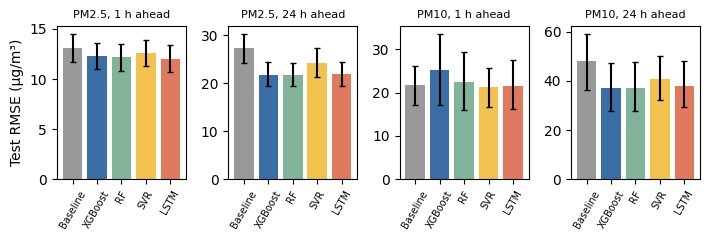

In [14]:

fig, axes = plt.subplots(1, 4, figsize=(7.2, 2.5))
colors = {"Baseline": "#999999", "XGBoost": "#3b6ea5", "Random Forest": "#81b29a", "SVR": "#f2c14e", "LSTM": "#e07a5f"}
for ax, (p, h) in zip(axes, [(p, h) for p in POLLUTANTS for h in HORIZONS]):
    y = target(test_rows, p, h)
    rmse = [metrics(y, pred[(p, h)][m]["test"])["RMSE"] for m in MODELS]
    ci = [bootstrap_ci(y, pred[(p, h)][m]["test"], n_boot=300)["RMSE"] for m in MODELS]
    err = np.array([[r - c[0], c[1] - r] for r, c in zip(rmse, ci)]).T
    ax.bar(range(len(MODELS)), rmse, yerr=err, capsize=2, color=[colors[m] for m in MODELS])
    ax.set_xticks(range(len(MODELS)))
    ax.set_xticklabels([m.replace("Random Forest", "RF") for m in MODELS], rotation=60, fontsize=7)
    ax.set_title(f"{'PM2.5' if p == 'pm25' else 'PM10'}, {h} h ahead", fontsize=8)
axes[0].set_ylabel("Test RMSE (µg/m³)")
plt.tight_layout(); plt.savefig(OUT + "/figures/fig2_rmse_ci.pdf"); plt.show()

## 7. Diebold–Mariano test
Compares two models on the same test hours.
1. For every hour compute the difference of squared errors: d = error_A² − error_B².
   If several cities share the same hour, the mean d for that hour is used.
2. If the models are equally good, the mean of d ≈ 0. The mean of d is divided by its standard error
   (corrected for the dependence between neighbouring hours with h−1 lags), which gives the statistic.
3. Harvey–Leybourne–Newbold small-sample correction; p-value from the t distribution.

A negative statistic means model A has the lower error. A model is called "better" only if p < 0.05.

In [15]:
def diebold_mariano(y, pred_a, pred_b, h, times):
    d = pd.Series((y - pred_a) ** 2 - (y - pred_b) ** 2).groupby(np.asarray(times)).mean().sort_index().values
    n = len(d)
    d_mean = d.mean()
    autocov = [np.sum((d[k:] - d_mean) * (d[:n - k] - d_mean)) / n for k in range(h)]
    variance = (autocov[0] + 2 * sum(autocov[1:])) / n
    dm = d_mean / np.sqrt(variance)
    dm = dm * np.sqrt((n + 1 - 2 * h + h * (h - 1) / n) / n)   # HLN correction
    p_value = 2 * stats.t.sf(abs(dm), df=n - 1)
    return dm, p_value

test_times = D.loc[test_rows, "time"].values
dm_table = []
for p in POLLUTANTS:
    for h in HORIZONS:
        y = target(test_rows, p, h)
        for i, a in enumerate(MODELS):
            for b in MODELS[i + 1:]:
                dm, pv = diebold_mariano(y, pred[(p, h)][a]["test"], pred[(p, h)][b]["test"], h, test_times)
                dm_table.append({"pollutant": p, "horizon": h, "model A": a, "model B": b, "DM": dm, "p-value": pv,
                                 "lower error": a if dm < 0 else b, "significant": pv < 0.05})
dm_table = pd.DataFrame(dm_table)
dm_table.to_csv(OUT + "/tables/table4_diebold_mariano.csv", index=False)
dm_table

,pollutant,horizon,model A,model B,DM,p-value,lower error,significant
0,pm25,1,Baseline,XGBoost,3.809695,1.407163e-04,XGBoost,True
1,pm25,1,Baseline,Random Forest,5.172231,2.398413e-07,Random Forest,True
2,pm25,1,Baseline,SVR,3.988846,6.729201e-05,SVR,True
3,pm25,1,Baseline,LSTM,4.352923,1.368674e-05,LSTM,True
4,pm25,1,XGBoost,Random Forest,1.717049,8.602875e-02,Random Forest,False
5,pm25,1,XGBoost,SVR,-1.382020,1.670238e-01,XGBoost,False
6,pm25,1,XGBoost,LSTM,2.060711,3.937941e-02,LSTM,True
7,pm25,1,Random Forest,SVR,-2.822750,4.779143e-03,Random Forest,True
8,pm25,1,Random Forest,LSTM,1.096823,2.727686e-01,LSTM,False
9,pm25,1,SVR,LSTM,3.321950,8.999732e-04,LSTM,True


In [16]:

best_model = {}
for p in POLLUTANTS:
    for h in HORIZONS:
        val_rmse = {m: metrics(target(val_rows, p, h), pred[(p, h)][m]["val"])["RMSE"] for m in MODELS[1:]}
        best_model[(p, h)] = min(val_rmse, key=val_rmse.get)
best_model

{('pm25', 1): 'LSTM',
 ('pm25', 24): 'LSTM',
 ('pm10', 1): 'LSTM',
 ('pm10', 24): 'XGBoost'}

## 8. RQ3: risk classes
Take the 24-h forecasts, compute their 24-h moving average and convert it into a class with the WHO thresholds
(the same way as for the observed data). Then compare with the observed class: Precision, Recall, F1 and confusion matrix.
The key number is the **Recall of the dangerous class**: the share of truly dangerous hours that the system detected.

In [17]:
def risk_predictions(model_name, h=24):
    out = []
    for city in CITY_NAMES:
        mask = (D.loc[test_rows, "city"] == city).values
        if not mask.any():
            continue
        g = D[D.city == city].set_index("time")
        target_times = pd.DatetimeIndex(D.loc[test_rows[mask], "time"]) + pd.Timedelta(hours=h)
        mean24 = {}
        for p in POLLUTANTS:
            s = pd.Series(pred[(p, h)][model_name]["test"][mask], index=target_times)
            mean24[p] = s.reindex(g.index).rolling(24, min_periods=24).mean()
        predicted = pd.Series(risk_class(mean24["pm25"], mean24["pm10"]), index=g.index)
        ok = predicted.notna() & g["obs_class"].notna()
        out.append(pd.DataFrame({"city": city, "time": g.index[ok],
                                 "observed": g["obs_class"][ok].astype(int).values,
                                 "predicted": predicted[ok].astype(int).values}))
    return pd.concat(out, ignore_index=True)

risk = {m: risk_predictions(m) for m in MODELS}
risk_table, conf = [], {}
for m in MODELS:
    r = risk[m]
    P, R, F, S = precision_recall_fscore_support(r.observed, r.predicted, labels=[0, 1, 2], zero_division=0)
    conf[m] = confusion_matrix(r.observed, r.predicted, labels=[0, 1, 2])
    for i, c in enumerate(CLASS_NAMES):
        risk_table.append({"model": m, "class": c, "precision": P[i], "recall": R[i], "F1": F[i], "hours": int(S[i])})
risk_table = pd.DataFrame(risk_table)
risk_table.to_csv(OUT + "/tables/table5_risk_classification.csv", index=False)
risk_table.pivot(index="model", columns="class", values="recall")[CLASS_NAMES].round(3)

class,safe,moderate,dangerous
model,,,
Baseline,0.841,0.440,0.648
LSTM,0.736,0.566,0.585
Random Forest,0.701,0.739,0.512
SVR,0.899,0.225,0.485
XGBoost,0.722,0.718,0.547


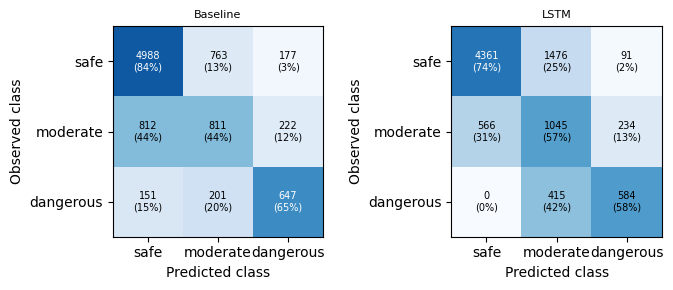

In [18]:

best24 = best_model[("pm25", 24)]
fig, axes = plt.subplots(1, 2, figsize=(7.0, 3.0))
for ax, m in zip(axes, ["Baseline", best24]):
    cm = conf[m]
    share = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
    ax.imshow(share, cmap="Blues", vmin=0, vmax=1)
    ax.grid(False)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{cm[i, j]}\n({100 * share[i, j]:.0f}%)", ha="center", va="center", fontsize=7,
                    color="white" if share[i, j] > 0.6 else "black")
    ax.set_xticks(range(3)); ax.set_xticklabels(CLASS_NAMES)
    ax.set_yticks(range(3)); ax.set_yticklabels(CLASS_NAMES)
    ax.set_xlabel("Predicted class"); ax.set_ylabel("Observed class"); ax.set_title(m, fontsize=8)
plt.tight_layout(); plt.savefig(OUT + "/figures/fig3_confusion_matrices.pdf"); plt.show()

## 9. Additional analyses
### By city (24 h)

In [19]:
test_city = D.loc[test_rows, "city"].values
city_table = []
for city in CITY_NAMES:
    mask = test_city == city
    for p in POLLUTANTS:
        y = target(test_rows, p, 24)[mask]
        row = {"city": city, "metric": f"MAE {p}"}
        for m in MODELS:
            row[m] = mean_absolute_error(y, pred[(p, 24)][m]["test"][mask])
        city_table.append(row)
    row = {"city": city, "metric": "recall dangerous"}
    for m in MODELS:
        r = risk[m][risk[m].city == city]
        n_dangerous = (r.observed == 2).sum()
        row[m] = ((r.observed == 2) & (r.predicted == 2)).sum() / n_dangerous if n_dangerous else np.nan
    row["dangerous hours"] = int(n_dangerous)
    city_table.append(row)
city_table = pd.DataFrame(city_table)
city_table.to_csv(OUT + "/tables/table6_by_city.csv", index=False)
city_table.round(2)

,city,metric,Baseline,XGBoost,Random Forest,SVR,LSTM,dangerous hours
0,Temirtau,MAE pm25,7.98,7.39,7.20,6.47,6.97,NaN
1,Temirtau,MAE pm10,10.09,9.34,9.39,8.31,9.08,NaN
2,Temirtau,recall dangerous,0.29,0.03,0.00,0.00,0.00,90.0
3,Pavlodar,MAE pm25,6.04,6.32,6.54,6.72,6.34,NaN
4,Pavlodar,MAE pm10,11.90,12.11,12.49,12.45,12.72,NaN
5,Pavlodar,recall dangerous,NaN,NaN,NaN,NaN,NaN,0.0
6,Oskemen,MAE pm25,19.56,17.42,17.64,16.98,17.61,NaN
7,Oskemen,MAE pm10,22.46,20.41,20.87,19.83,20.88,NaN
8,Oskemen,recall dangerous,0.62,0.39,0.42,0.28,0.43,495.0
9,Karaganda,MAE pm25,28.74,23.76,24.45,28.71,23.30,NaN


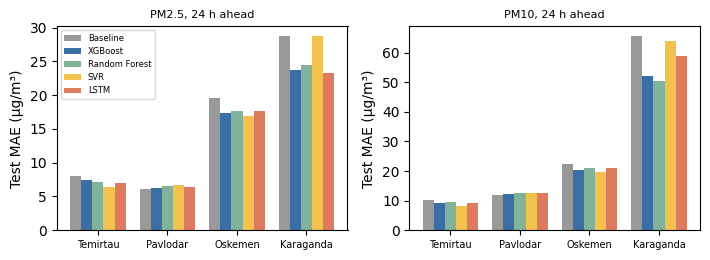

In [20]:

fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.7))
width = 0.8 / len(MODELS)
for ax, p in zip(axes, POLLUTANTS):
    t = city_table[city_table.metric == f"MAE {p}"]
    for i, m in enumerate(MODELS):
        ax.bar(np.arange(len(CITY_NAMES)) + i * width, t[m].values, width, label=m, color=colors[m])
    ax.set_xticks(np.arange(len(CITY_NAMES)) + 0.4 - width / 2)
    ax.set_xticklabels(CITY_NAMES, fontsize=7)
    ax.set_ylabel("Test MAE (µg/m³)")
    ax.set_title(f"{'PM2.5' if p == 'pm25' else 'PM10'}, 24 h ahead", fontsize=8)
axes[0].legend(fontsize=6)
plt.tight_layout(); plt.savefig(OUT + "/figures/fig4_mae_by_city.pdf"); plt.show()

### By season (24 h)

In [21]:
test_season = D.loc[test_rows, "season"].values
season_table = []
for p in POLLUTANTS:
    y = target(test_rows, p, 24)
    for m in MODELS:
        row = {"pollutant": p, "model": m}
        for s in ["winter", "spring", "summer", "autumn"]:
            mask = test_season == s
            row[s] = mean_absolute_error(y[mask], pred[(p, 24)][m]["test"][mask]) if mask.any() else np.nan
        season_table.append(row)
season_table = pd.DataFrame(season_table)
season_table.to_csv(OUT + "/tables/table7_mae_by_season.csv", index=False)
print("test hours per season:", pd.Series(test_season).value_counts().to_dict())
season_table.round(2)

test hours per season: {'autumn': 6047, 'summer': 1954, 'winter': 1456, 'spring': 289}


,pollutant,model,winter,spring,summer,autumn
0,pm25,Baseline,25.85,9.28,3.61,13.56
1,pm25,XGBoost,22.10,9.11,3.78,12.38
2,pm25,Random Forest,22.07,9.04,3.68,12.68
3,pm25,SVR,24.04,8.13,3.38,12.41
4,pm25,LSTM,23.04,8.94,3.14,12.24
5,pm10,Baseline,30.82,14.05,5.76,22.37
6,pm10,XGBoost,29.19,13.35,5.59,19.46
7,pm10,Random Forest,28.11,13.62,6.21,19.71
8,pm10,SVR,35.75,12.64,5.43,19.17
9,pm10,LSTM,34.39,13.45,5.61,19.69


### SHAP: which features influence the XGBoost forecast most (PM2.5, 24 h)

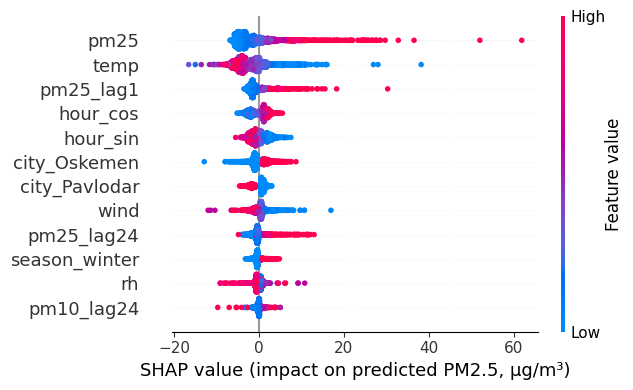

In [22]:
if RUN_SHAP:
    import shap
    X_sample = pd.DataFrame(X_test, columns=FEATURES).sample(min(2000, len(test_rows)), random_state=0)
    shap_values = shap.TreeExplainer(xgb_for_shap[("pm25", 24)]).shap_values(X_sample)
    plt.figure()
    shap.summary_plot(shap_values, X_sample, show=False, max_display=12, plot_size=(6.5, 4))
    plt.xlabel("SHAP value (impact on predicted PM2.5, µg/m³)")
    plt.tight_layout(); plt.savefig(OUT + "/figures/fig5_shap_xgb_pm25_h24.pdf"); plt.show()
    pd.Series(np.abs(shap_values).mean(axis=0), index=FEATURES).sort_values(ascending=False).to_csv(OUT + "/tables/shap_importance.csv")

## 10. Error analysis
Where the best model makes the largest errors: the worst week and the 10 largest errors.

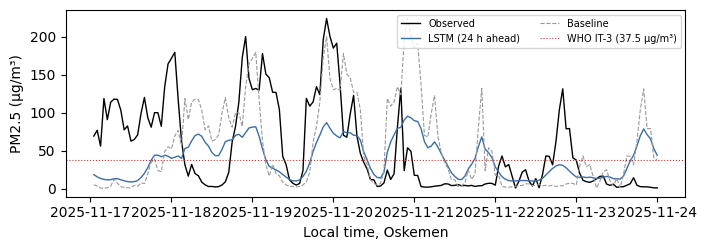

Worst week: Oskemen 2025-11-17 01:00:00 - 2025-11-24 00:00:00
MAE by observed concentration:
                 count   mean
observed                     
(0.0, 15.0]       7226   7.71
(15.0, 37.5]      1510  10.43
(37.5, 75.0]       632  27.07
(75.0, 10000.0]    357  77.29
dangerous hours: 999  missed: 415  false alarms: 325


,city,time,season,target_time,observed,predicted,baseline,abs_error
9697,Karaganda,2021-02-25 22:00:00,winter,2021-02-26 22:00:00,393.020000,37.720235,18.750000,355.299765
9698,Karaganda,2021-02-25 23:00:00,winter,2021-02-26 23:00:00,321.560000,36.143769,22.170000,285.416231
9415,Karaganda,2021-02-12 19:00:00,winter,2021-02-13 19:00:00,284.250000,58.386090,148.210000,225.863910
9417,Karaganda,2021-02-12 21:00:00,winter,2021-02-13 21:00:00,224.050000,53.800444,52.900000,170.249556
9699,Karaganda,2021-02-26 00:00:00,winter,2021-02-27 00:00:00,195.950000,34.887109,25.590000,161.062891
8646,Oskemen,2025-12-13 20:00:00,winter,2025-12-14 20:00:00,188.647672,28.717160,3.046491,159.930512
7263,Oskemen,2025-10-15 20:00:00,autumn,2025-10-16 20:00:00,230.183333,71.297742,75.550000,158.885592
8393,Oskemen,2025-12-01 22:00:00,winter,2025-12-02 22:00:00,203.488889,48.393901,14.761111,155.094988
2128,Temirtau,2025-11-18 01:00:00,autumn,2025-11-19 01:00:00,174.900000,25.003790,47.916667,149.896210
9029,Karaganda,2020-11-16 21:00:00,autumn,2020-11-17 21:00:00,184.565000,37.197935,23.330000,147.367065


In [23]:
m = best_model[("pm25", 24)]
err = D.loc[test_rows, ["city", "time", "season"]].reset_index(drop=True)
err["target_time"] = err["time"] + pd.Timedelta(hours=24)
err["observed"] = target(test_rows, "pm25", 24)
err["predicted"] = pred[("pm25", 24)][m]["test"]
err["baseline"] = pred[("pm25", 24)]["Baseline"]["test"]
err["abs_error"] = (err.observed - err.predicted).abs()


worst = None
for city, g in err.groupby("city"):
    weekly = g.set_index("target_time")["abs_error"].sort_index().rolling("168h", min_periods=120).mean()
    if len(weekly.dropna()) and (worst is None or weekly.max() > worst[2]):
        worst = (city, weekly.idxmax(), weekly.max())
city, end = worst[0], worst[1]
start = end - pd.Timedelta(hours=167)
g = err[(err.city == city) & (err.target_time >= start) & (err.target_time <= end)].sort_values("target_time")

fig, ax = plt.subplots(figsize=(7.2, 2.6))
ax.plot(g.target_time, g.observed, color="black", lw=1, label="Observed")
ax.plot(g.target_time, g.predicted, color="#3b6ea5", lw=1, label=f"{m} (24 h ahead)")
ax.plot(g.target_time, g.baseline, color="#999999", lw=0.8, ls="--", label="Baseline")
ax.axhline(37.5, color="#c0392b", lw=0.8, ls=":", label="WHO IT-3 (37.5 µg/m³)")
ax.set_ylabel("PM2.5 (µg/m³)"); ax.set_xlabel(f"Local time, {city}"); ax.legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.savefig(OUT + "/figures/fig6_worst_week_pm25.pdf"); plt.show()
print("Worst week:", city, start, "-", end)

top10 = err.sort_values("abs_error", ascending=False).head(10)
top10.to_csv(OUT + "/tables/table9_top10_errors.csv", index=False)
print("MAE by observed concentration:")
print(err.groupby(pd.cut(err.observed, [0, 15, 37.5, 75, 1e4]))["abs_error"].agg(["count", "mean"]).round(2))
r = risk[m]
print("dangerous hours:", (r.observed == 2).sum(), " missed:", ((r.observed == 2) & (r.predicted < 2)).sum(),
      " false alarms:", ((r.observed < 2) & (r.predicted == 2)).sum())
top10

## 11. Versions, hardware, run time and download of results

In [24]:
import sys, sklearn, scipy
info = {"python": sys.version.split()[0], "numpy": np.__version__, "pandas": pd.__version__,
        "scikit-learn": sklearn.__version__, "xgboost": xgb.__version__, "scipy": scipy.__version__,
        "seeds": SEEDS, "best settings": best_setting,
        "best model (validation)": {f"{p} h{h}": v for (p, h), v in best_model.items()},
        "samples": {"train": len(train_rows), "val": len(val_rows), "test": len(test_rows)},
        "runtime_min": round((time.time() - start_time) / 60, 1),
        "gpu": os.popen("nvidia-smi --query-gpu=name --format=csv,noheader 2>/dev/null").read().strip() or "none",
        "cpu": os.popen("lscpu 2>/dev/null | grep 'Model name'").read().strip()}
if RUN_LSTM: info["tensorflow"] = tf.__version__
if RUN_SHAP: info["shap"] = shap.__version__
json.dump(info, open(OUT + "/run_info.json", "w"), indent=1, default=str)
print(json.dumps(info, indent=1, default=str))

with zipfile.ZipFile("/content/results.zip", "w") as z:
    for folder, _, files in os.walk(OUT):
        for f in files:
            z.write(os.path.join(folder, f), os.path.relpath(os.path.join(folder, f), "/content"))
try:
    from google.colab import files
    files.download("/content/results.zip")
except ImportError:
    print("saved /content/results.zip")

{
 "python": "3.13.15",
 "numpy": "2.1.3",
 "pandas": "2.2.3",
 "scikit-learn": "1.6.1",
 "xgboost": "3.4.1",
 "scipy": "1.16.3",
 "seeds": [
  0,
  1,
  2,
  3,
  4
 ],
 "best settings": {
  "pm25 h1 XGBoost": {
   "n_estimators": 300,
   "max_depth": 4
  },
  "pm25 h1 Random Forest": {
   "max_depth": null
  },
  "pm25 h1 SVR": {
   "kernel": "linear"
  },
  "pm25 h1 LSTM": {
   "window": 24
  },
  "pm25 h24 XGBoost": {
   "n_estimators": 300,
   "max_depth": 4
  },
  "pm25 h24 Random Forest": {
   "max_depth": 15
  },
  "pm25 h24 SVR": {
   "kernel": "rbf"
  },
  "pm25 h24 LSTM": {
   "window": 12
  },
  "pm10 h1 XGBoost": {
   "n_estimators": 300,
   "max_depth": 4
  },
  "pm10 h1 Random Forest": {
   "max_depth": 15
  },
  "pm10 h1 SVR": {
   "kernel": "linear"
  },
  "pm10 h1 LSTM": {
   "window": 24
  },
  "pm10 h24 XGBoost": {
   "n_estimators": 300,
   "max_depth": 4
  },
  "pm10 h24 Random Forest": {
   "max_depth": 15
  },
  "pm10 h24 SVR": {
   "kernel": "rbf"
  },
  "pm10 

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>